# Predicting Subscription Renewal Risk and Customer Churn Using Machine Learning

**Author:** Trilok Reddy Arava  
**Program:** UC Berkeley Professional Certificate in Machine Learning and Artificial Intelligence  
**Assignment:** Required Capstone Assignment 20.1 — Initial Report and Exploratory Data Analysis (EDA)

## Executive Summary
This project investigates whether customer, subscription, and billing characteristics can help identify customers at elevated risk of churn. The IBM Telco Customer Churn dataset contains **7,043 customer records**; **1,869 customers (26.54%)** are labeled as churned. Exploratory analysis identifies meaningful differences across contract types, payment methods, tenure, and internet services. An interpretable **Logistic Regression baseline** achieves **80.55% accuracy, 55.88% churn recall, and 0.8419 ROC-AUC** on a held-out test set. These findings inform potential retention prioritization; they do not establish causality.

## Business Rationale
Subscription businesses depend on recurring relationships. Identifying customers at elevated churn risk may help retention teams prioritize limited outreach resources, investigate customer friction, and improve forecasting. Missing a customer who subsequently churns can represent a missed outreach opportunity, while unnecessary outreach has a cost.

## Research Question
**Can machine learning identify subscription-based customers at greatest risk of churn and explain the factors associated with that risk, enabling businesses to prioritize retention efforts and improve renewal outcomes?**

## Data Source and Scope
The public **IBM Telco Customer Churn** dataset includes customer demographics, tenure, contract type, subscribed services, monthly and total charges, payment method, and a binary **Churn (Yes/No)** outcome. It is used as a **proxy for subscription renewal risk**, not as a record of Salesforce opportunities or verified SaaS renewal outcomes.

## Methodology — CRISP-DM
This notebook follows **CRISP-DM**: (1) business understanding, (2) data understanding, (3) data preparation, (4) modeling, (5) evaluation, and (6) interpretation and recommendations. **Logistic Regression is the single baseline ML algorithm for Module 20.1.** Multiple model comparisons, cross-validation, and hyperparameter tuning are planned for Module 24.

---


## 1. Setup and reproducibility
Run this notebook from the project folder or from `notebooks/`. The dataset is included in `data/`.

In [1]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display
from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
                             roc_auc_score, average_precision_score, classification_report,
                             ConfusionMatrixDisplay, RocCurveDisplay, PrecisionRecallDisplay)

sns.set_theme(style="whitegrid")
SEED = 42
PROJECT_ROOT = Path.cwd() if (Path.cwd() / 'data' / 'Telco-Customer-Churn.csv').exists() else Path.cwd().parent
DATA_FILE = PROJECT_ROOT / 'data' / 'Telco-Customer-Churn.csv'
FIG_DIR = PROJECT_ROOT / 'outputs' / 'figures'
REPORT_DIR = PROJECT_ROOT / 'outputs' / 'reports'
FIG_DIR.mkdir(parents=True, exist_ok=True)
REPORT_DIR.mkdir(parents=True, exist_ok=True)
assert DATA_FILE.exists(), f'Dataset not found: {DATA_FILE}'
print('Project root:', PROJECT_ROOT)

Project root: /Users/aravat/Documents/Python/Working/Module_20/Assignment_20_2_Capstone_Initial_Report_EDA


## 2. Data understanding and quality audit

In [2]:
raw = pd.read_csv(DATA_FILE)
print('Shape:', raw.shape)
display(raw.head())
print('Column types:')
display(raw.dtypes.to_frame('dtype'))
print('Churn counts:')
display(raw['Churn'].value_counts().rename_axis('Churn').to_frame('count'))
print('Duplicate rows:', raw.duplicated().sum())
print('Duplicate customer IDs:', raw['customerID'].duplicated().sum())
print('Raw missing values:', raw.isna().sum().sum())
print('Blank TotalCharges:', raw['TotalCharges'].astype(str).str.strip().eq('').sum())

Shape: (7043, 21)


,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,...,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,...,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,...,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


Column types:


,dtype
customerID,str
gender,str
SeniorCitizen,int64
Partner,str
Dependents,str
tenure,int64
PhoneService,str
MultipleLines,str
InternetService,str
OnlineSecurity,str


Churn counts:


,count
Churn,
No,5174
Yes,1869


Duplicate rows: 0
Duplicate customer IDs: 0
Raw missing values: 0
Blank TotalCharges: 11


## 3. Data cleaning
`TotalCharges` is stored as text and includes blank entries. We convert blanks to missing values. Customer identifiers are excluded from modeling. For rows with missing `TotalCharges`, we retain them and impute **inside the training-only preprocessing pipeline**, avoiding leakage. Duplicate customer IDs, if any, are removed. We do not automatically discard numerical outliers: unusual charges may be legitimate.

In [3]:
df = raw.drop_duplicates(subset='customerID').copy()
df['TotalCharges'] = pd.to_numeric(df['TotalCharges'].replace(r'^\s*$', np.nan, regex=True), errors='coerce')
df['ChurnFlag'] = df['Churn'].map({'No': 0, 'Yes': 1}).astype(int)
assert df['ChurnFlag'].notna().all()
print('Cleaned shape:', df.shape)
print('Missing values after conversion:')
display(df.isna().sum().loc[lambda s: s.gt(0)].to_frame('missing_count'))
display(df[['tenure', 'MonthlyCharges', 'TotalCharges']].describe().round(2))

Cleaned shape: (7043, 22)
Missing values after conversion:


,missing_count
TotalCharges,11


,tenure,MonthlyCharges,TotalCharges
count,7043.00,7043.00,7032.00
mean,32.37,64.76,2283.30
std,24.56,30.09,2266.77
min,0.00,18.25,18.80
25%,9.00,35.50,401.45
50%,29.00,70.35,1397.48
75%,55.00,89.85,3794.74
max,72.00,118.75,8684.80


### EDA objectives and interpretation
The following charts compare churn across categorical groups and describe numerical distributions. Group-level churn rates use the number of customers in each group as the denominator; they should not be interpreted as causal effects. The overall churn distribution also reveals class imbalance, motivating stratification and metrics beyond accuracy.


## 4. Exploratory data analysis: distributions and customer segments

,customers,percentage
Churn,,
No,5174,73.46
Yes,1869,26.54


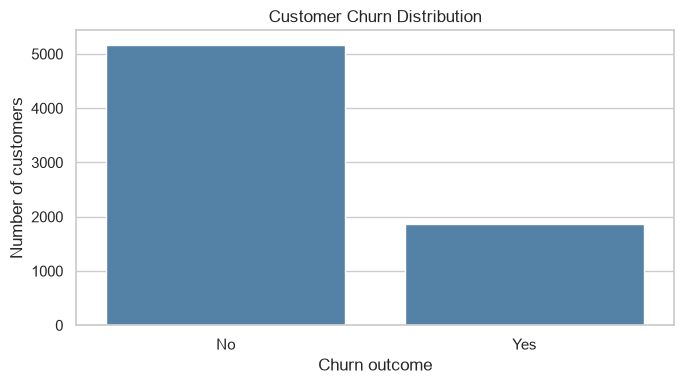

In [4]:
churn_summary = df.groupby('Churn', observed=True).size().rename('customers').to_frame()
churn_summary['percentage'] = (100 * churn_summary['customers'] / len(df)).round(2)
display(churn_summary)
fig, ax = plt.subplots(figsize=(7, 4))
sns.countplot(data=df, x='Churn', order=['No', 'Yes'], color='steelblue', ax=ax)
ax.set(title='Customer Churn Distribution', xlabel='Churn outcome', ylabel='Number of customers')
fig.tight_layout(); fig.savefig(FIG_DIR / '01_churn_distribution.png', dpi=160); plt.show()

Churn by Contract:


,customers,churn_rate_pct
Contract,,
Month-to-month,3875,42.71
One year,1473,11.27
Two year,1695,2.83


Churn by PaymentMethod:


,customers,churn_rate_pct
PaymentMethod,,
Electronic check,2365,45.29
Mailed check,1612,19.11
Bank transfer (automatic),1544,16.71
Credit card (automatic),1522,15.24


Churn by InternetService:


,customers,churn_rate_pct
InternetService,,
Fiber optic,3096,41.89
DSL,2421,18.96
No,1526,7.40


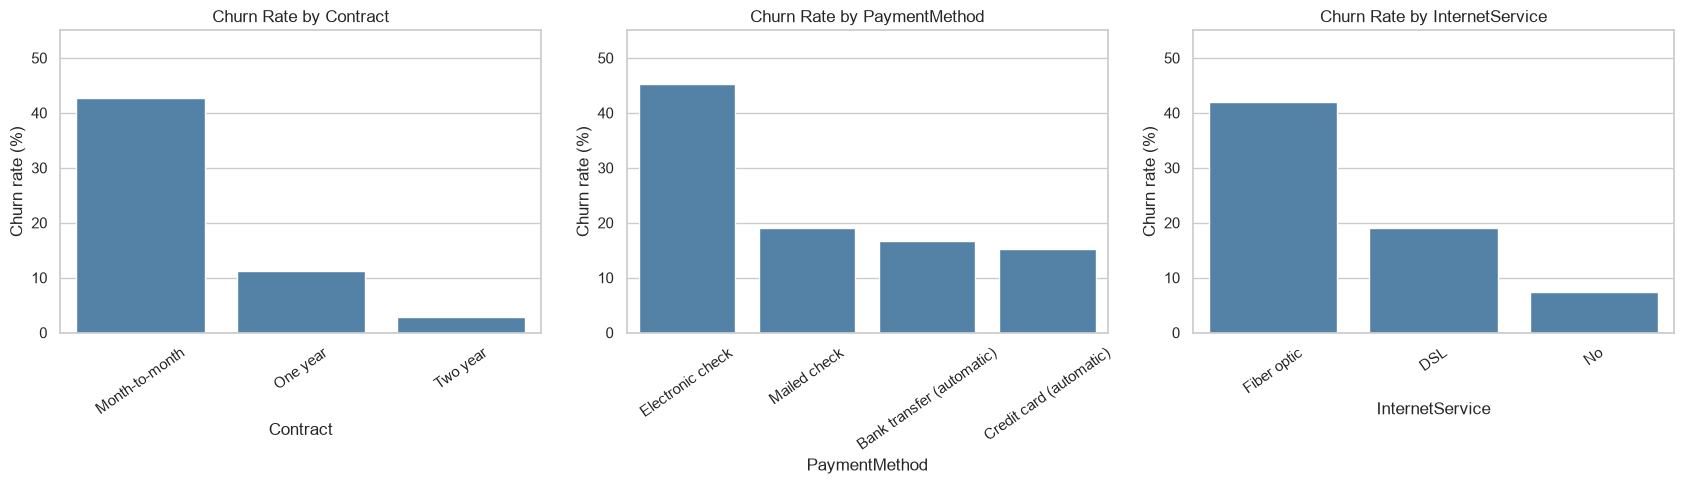

In [5]:
def segment_churn(column):
    return (df.groupby(column, observed=True)['ChurnFlag']
              .agg(customers='size', churn_rate='mean')
              .assign(churn_rate_pct=lambda x: (x.churn_rate * 100).round(2))
              .sort_values('churn_rate', ascending=False))

for col in ['Contract', 'PaymentMethod', 'InternetService']:
    print(f'Churn by {col}:')
    display(segment_churn(col)[['customers', 'churn_rate_pct']])

fig, axes = plt.subplots(1, 3, figsize=(17, 5))
for ax, col in zip(axes, ['Contract', 'PaymentMethod', 'InternetService']):
    s = segment_churn(col)
    sns.barplot(x=s.index.astype(str), y=s['churn_rate_pct'], color='steelblue', ax=ax)
    ax.set(title=f'Churn Rate by {col}', xlabel=col, ylabel='Churn rate (%)', ylim=(0, max(55, s.churn_rate_pct.max() * 1.15)))
    ax.tick_params(axis='x', rotation=35)
fig.tight_layout(); fig.savefig(FIG_DIR / '02_categorical_churn_rates.png', dpi=160, bbox_inches='tight'); plt.show()

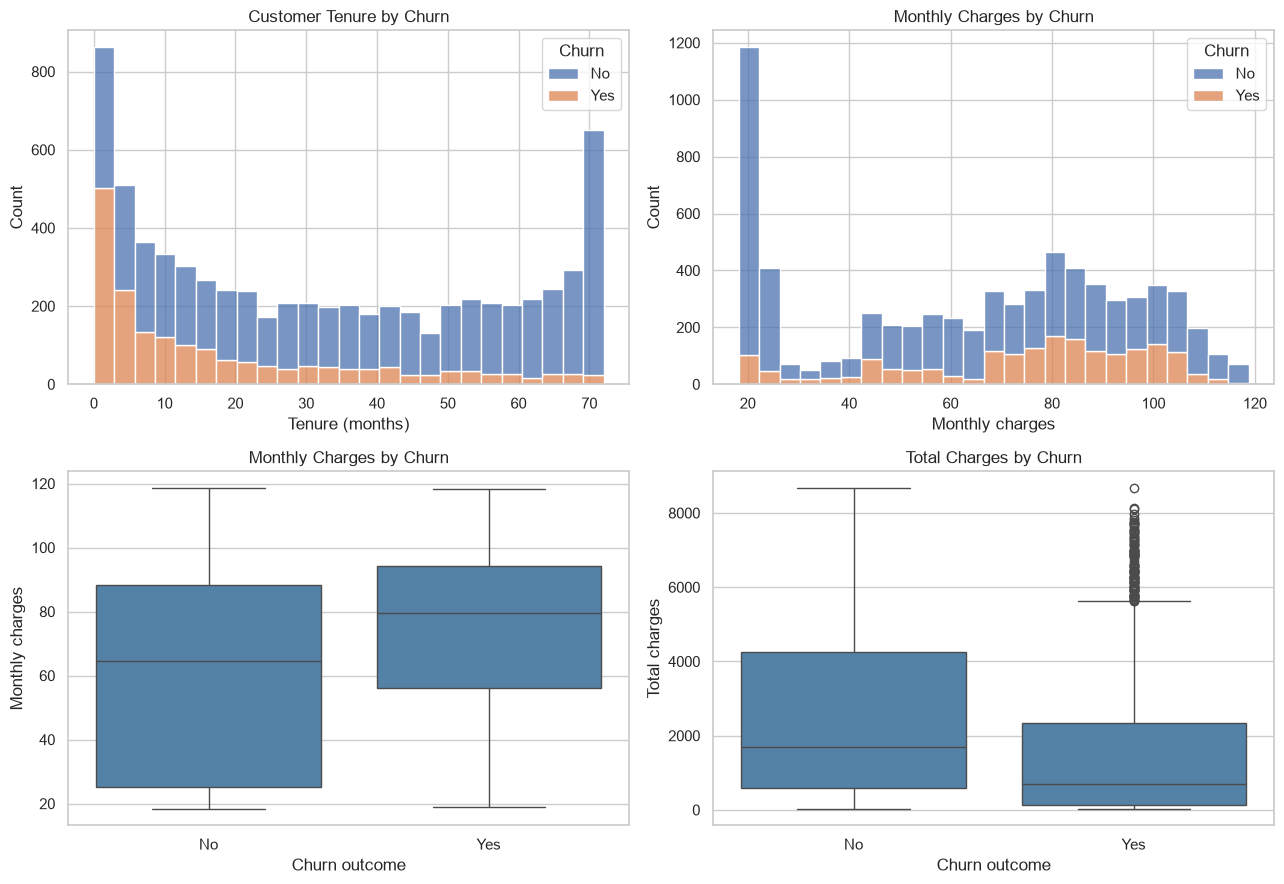

In [6]:
fig, axes = plt.subplots(2, 2, figsize=(13, 9))
sns.histplot(data=df, x='tenure', hue='Churn', bins=25, multiple='stack', ax=axes[0, 0])
axes[0, 0].set(title='Customer Tenure by Churn', xlabel='Tenure (months)')
sns.histplot(data=df, x='MonthlyCharges', hue='Churn', bins=25, multiple='stack', ax=axes[0, 1])
axes[0, 1].set(title='Monthly Charges by Churn', xlabel='Monthly charges')
sns.boxplot(data=df, x='Churn', y='MonthlyCharges', order=['No', 'Yes'], color='steelblue', ax=axes[1, 0])
axes[1, 0].set(title='Monthly Charges by Churn', xlabel='Churn outcome', ylabel='Monthly charges')
sns.boxplot(data=df, x='Churn', y='TotalCharges', order=['No', 'Yes'], color='steelblue', ax=axes[1, 1])
axes[1, 1].set(title='Total Charges by Churn', xlabel='Churn outcome', ylabel='Total charges')
fig.tight_layout(); fig.savefig(FIG_DIR / '03_numeric_distributions.png', dpi=160); plt.show()

### Interpretation of numerical distributions
Compare the shapes and spreads of tenure, monthly charges, and total charges across churn outcomes. Because the two classes differ in size, the histogram counts alone do not represent within-group churn probabilities. The boxplots and correlation matrix provide complementary descriptive views, not evidence of causal relationships.


## 5. Outlier analysis and numeric relationships
The IQR method flags observations for review, not automatic removal. A low or high charge can be a valid customer observation.

,feature,lower_iqr_bound,upper_iqr_bound,flagged_rows
0,tenure,-60.00,124.00,0
1,MonthlyCharges,-46.02,171.38,0
2,TotalCharges,-4688.48,8884.67,0


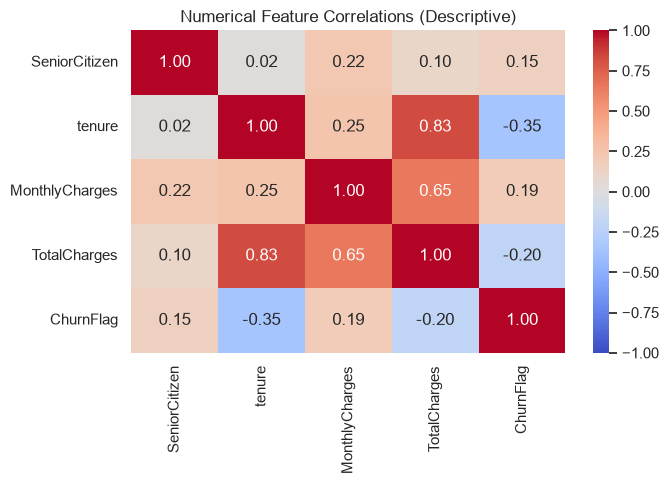

In [7]:
outlier_rows = []
for col in ['tenure', 'MonthlyCharges', 'TotalCharges']:
    s = df[col].dropna()
    q1, q3 = s.quantile([0.25, 0.75]); iqr = q3 - q1
    lower, upper = q1 - 1.5 * iqr, q3 + 1.5 * iqr
    outlier_rows.append({'feature': col, 'lower_iqr_bound': lower, 'upper_iqr_bound': upper,
                         'flagged_rows': int(((s < lower) | (s > upper)).sum())})
outliers = pd.DataFrame(outlier_rows)
display(outliers.round(2))
outliers.to_csv(REPORT_DIR / 'outlier_audit.csv', index=False)

corr = df[['SeniorCitizen', 'tenure', 'MonthlyCharges', 'TotalCharges', 'ChurnFlag']].corr(numeric_only=True)
fig, ax = plt.subplots(figsize=(7, 5))
sns.heatmap(corr, annot=True, fmt='.2f', cmap='coolwarm', vmin=-1, vmax=1, ax=ax)
ax.set(title='Numerical Feature Correlations (Descriptive)')
fig.tight_layout(); fig.savefig(FIG_DIR / '04_numeric_correlations.png', dpi=160); plt.show()

### Outlier decision rationale
The interquartile-range (IQR) audit identifies unusually extreme numerical values for inspection. An outlier flag is **not** proof of an error: a high total charge may reflect a long customer relationship. The baseline retains legitimate observations rather than removing them solely on statistical grounds.


## 6. Feature engineering
We create interpretable customer segments: tenure groups, monthly-charge bands, and a count of subscribed add-on services. Segment boundaries are fixed business-readable bins, not learned from the target. These features are descriptive; some overlap with original predictors, so coefficient interpretation must account for correlated variables.

Churn by TenureGroup:


,customers,churn_rate_pct
TenureGroup,,
0-12 months,2186,47.44
13-24 months,1024,28.71
25-48 months,1594,20.39
49-72 months,2239,9.51


Churn by MonthlyChargeBand:


,customers,churn_rate_pct
MonthlyChargeBand,,
Over $70,3583,35.36
$35-$70,1725,23.94
Under $35,1735,10.89


Churn by AddOnServiceCount:


,customers,churn_rate_pct
AddOnServiceCount,,
1,966,45.76
2,1033,35.82
3,1118,27.37
4,852,22.30
0,2219,21.41
5,571,12.43
6,284,5.28


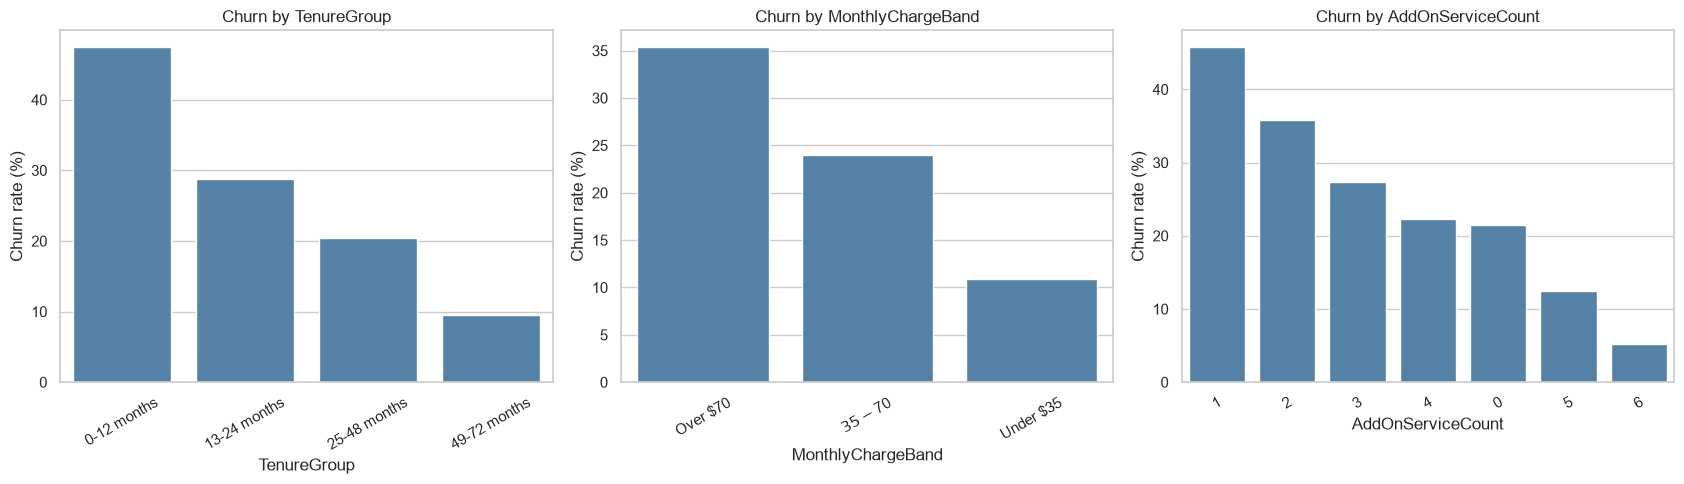

In [8]:
df['TenureGroup'] = pd.cut(df['tenure'], bins=[-1, 12, 24, 48, 72], labels=['0-12 months', '13-24 months', '25-48 months', '49-72 months'])
df['MonthlyChargeBand'] = pd.cut(df['MonthlyCharges'], bins=[-np.inf, 35, 70, np.inf], labels=['Under $35', '$35-$70', 'Over $70'])
service_cols = ['OnlineSecurity', 'OnlineBackup', 'DeviceProtection', 'TechSupport', 'StreamingTV', 'StreamingMovies']
df['AddOnServiceCount'] = df[service_cols].eq('Yes').sum(axis=1)
for col in ['TenureGroup', 'MonthlyChargeBand', 'AddOnServiceCount']:
    print(f'Churn by {col}:')
    display(segment_churn(col)[['customers', 'churn_rate_pct']])
fig, axes = plt.subplots(1, 3, figsize=(17, 5))
for ax, col in zip(axes, ['TenureGroup', 'MonthlyChargeBand', 'AddOnServiceCount']):
    s = segment_churn(col)
    sns.barplot(x=s.index.astype(str), y=s['churn_rate_pct'], color='steelblue', ax=ax)
    ax.set(title=f'Churn by {col}', xlabel=col, ylabel='Churn rate (%)')
    ax.tick_params(axis='x', rotation=30)
fig.tight_layout(); fig.savefig(FIG_DIR / '05_engineered_features.png', dpi=160, bbox_inches='tight'); plt.show()

### Feature engineering rationale
**TenureGroup** makes early-versus-long-tenure patterns easier to communicate; **MonthlyChargeBand** summarizes pricing segments; **AddOnServiceCount** aggregates the number of optional services. The first two are used for descriptive EDA, while the service count is included among the baseline predictors. Fixed bins support reproducibility; no target-based feature selection is performed using test outcomes.


## 7. Baseline model — Logistic Regression
We use an 80/20 **stratified** split. All imputation, scaling, and categorical encoding are fitted on training data only through a pipeline. We exclude `customerID`, the original text `Churn` column, and `ChurnFlag` from predictors. For a clean baseline, we use original predictor fields plus **AddOnServiceCount**, leaving descriptive tenure and charge bins out of the model to avoid redundant representations. We use the default 0.50 probability threshold and do not tune against the test set.

### Baseline model selection and evaluation rationale
**Why Logistic Regression?** Churn is binary, and Logistic Regression offers an interpretable probability-based benchmark for later models. An **80/20 stratified split** maintains class proportions. Missing-value imputation, numerical scaling, and categorical encoding occur within the fitted training pipeline to reduce leakage risk.

**Metrics:** Accuracy summarizes overall correctness, **precision** measures how many flagged customers actually churn, **recall** measures how many actual churners are found, **F1** balances precision and recall, and **ROC-AUC** evaluates ranking across thresholds. Recall is especially relevant for missed retention opportunities, but precision must also be considered to manage outreach effort. The default decision threshold is 0.50.


In [9]:
target = df['ChurnFlag']
features = df.drop(columns=['customerID', 'Churn', 'ChurnFlag', 'TenureGroup', 'MonthlyChargeBand'])
numeric_cols = features.select_dtypes(include=np.number).columns.tolist()
categorical_cols = features.select_dtypes(exclude=np.number).columns.tolist()
X_train, X_test, y_train, y_test = train_test_split(features, target, test_size=0.20, stratify=target, random_state=SEED)

numeric_pipe = Pipeline([('imputer', SimpleImputer(strategy='median')), ('scaler', StandardScaler())])
categorical_pipe = Pipeline([('imputer', SimpleImputer(strategy='most_frequent')),
                             ('onehot', OneHotEncoder(handle_unknown='ignore'))])
preprocessor = ColumnTransformer([('num', numeric_pipe, numeric_cols), ('cat', categorical_pipe, categorical_cols)])
model = Pipeline([('preprocessor', preprocessor), ('classifier', LogisticRegression(max_iter=2000, random_state=SEED))])
model.fit(X_train, y_train)
y_pred = model.predict(X_test)
y_prob = model.predict_proba(X_test)[:, 1]
metrics = {'accuracy': accuracy_score(y_test, y_pred), 'precision': precision_score(y_test, y_pred),
           'recall': recall_score(y_test, y_pred), 'f1': f1_score(y_test, y_pred),
           'roc_auc': roc_auc_score(y_test, y_prob), 'average_precision': average_precision_score(y_test, y_prob)}
print('Training rows:', len(X_train), 'Test rows:', len(X_test))
display(pd.DataFrame([metrics]).round(4))
print(classification_report(y_test, y_pred, target_names=['No churn', 'Churn']))
pd.DataFrame([{'model': 'Logistic Regression', **metrics}]).to_csv(REPORT_DIR / 'baseline_metrics.csv', index=False)

Training rows: 5634 Test rows: 1409


,accuracy,precision,recall,f1,roc_auc,average_precision
0,0.8055,0.6572,0.5588,0.604,0.8419,0.6334


              precision    recall  f1-score   support

    No churn       0.85      0.89      0.87      1035
       Churn       0.66      0.56      0.60       374

    accuracy                           0.81      1409
   macro avg       0.75      0.73      0.74      1409
weighted avg       0.80      0.81      0.80      1409



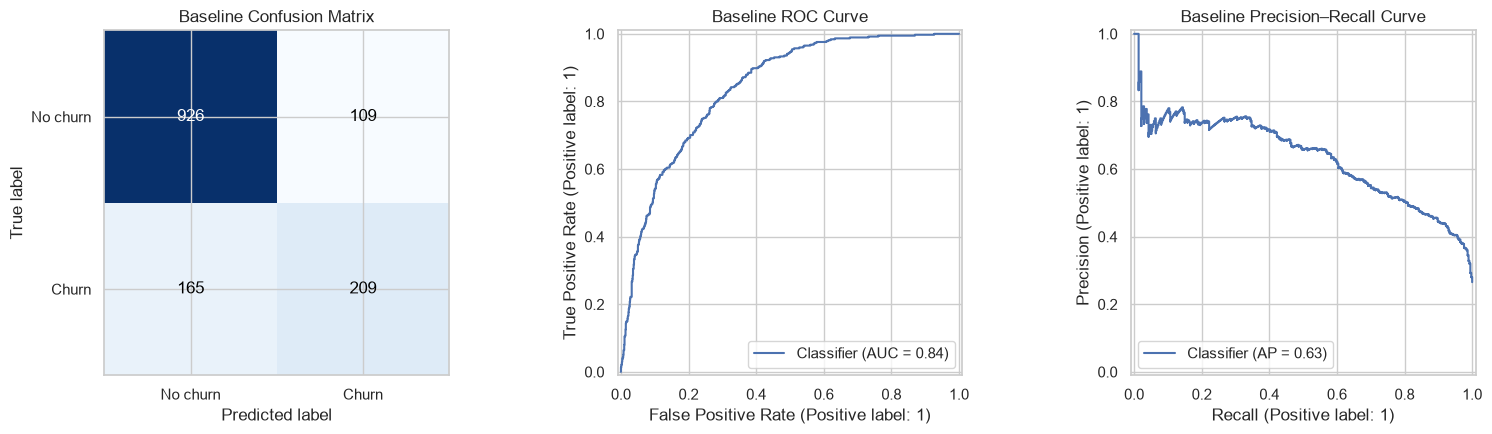

In [14]:
from sklearn.metrics import (
    ConfusionMatrixDisplay,
    RocCurveDisplay,
    PrecisionRecallDisplay
)
import matplotlib.pyplot as plt

# Create three plots in a single row
fig, axes = plt.subplots(1, 3, figsize=(16, 4.5))

# 1. Confusion Matrix
cm_display = ConfusionMatrixDisplay.from_predictions(
    y_test,
    y_pred,
    display_labels=["No churn", "Churn"],
    cmap="Blues",
    colorbar=False,
    ax=axes[0]
)

axes[0].set_title("Baseline Confusion Matrix")

# Improve annotation contrast based on background color
for text, value in zip(cm_display.text_.ravel(), cm_display.confusion_matrix.ravel()):
    text.set_color("white" if value > cm_display.confusion_matrix.max() / 2 else "black")

# 2. ROC Curve
RocCurveDisplay.from_predictions(
    y_test,
    y_prob,
    ax=axes[1]
)
axes[1].set_title("Baseline ROC Curve")

# 3. Precision–Recall Curve
PrecisionRecallDisplay.from_predictions(
    y_test,
    y_prob,
    ax=axes[2]
)
axes[2].set_title("Baseline Precision–Recall Curve")

# Adjust spacing and save the updated figure
fig.tight_layout()

fig.savefig(
    FIG_DIR / "06_baseline_evaluation.png",
    dpi=160,
    bbox_inches="tight"
)

plt.show()

### Baseline evaluation — what the confusion matrix means
On the held-out test set, the model produced **926 true negatives**, **109 false positives**, **165 false negatives**, and **209 true positives**. It therefore detected **209 of 374** actual churners (**55.88% recall**), while missing 165. The ROC and precision–recall curves illustrate threshold-dependent tradeoffs; the current results are a baseline, not a production-ready decision policy.


## 8. Interpreting model associations
Logistic Regression coefficients describe associations with predicted churn **conditional on other encoded predictors**, not causal effects. One-hot encoded categories are compared to other categories within the representation; correlated features can make individual coefficients unstable.

,feature,coefficient,abs_coefficient
1,num__tenure,-1.240,1.240
39,cat__Contract_Two year,-0.774,0.774
16,cat__InternetService_DSL,-0.684,0.684
17,cat__InternetService_Fiber optic,0.647,0.647
2,num__MonthlyCharges,-0.641,0.641
37,cat__Contract_Month-to-month,0.579,0.579
3,num__TotalCharges,0.515,0.515
40,cat__PaperlessBilling_No,-0.345,0.345
35,cat__StreamingMovies_No internet service,-0.281,0.281
32,cat__StreamingTV_No internet service,-0.281,0.281


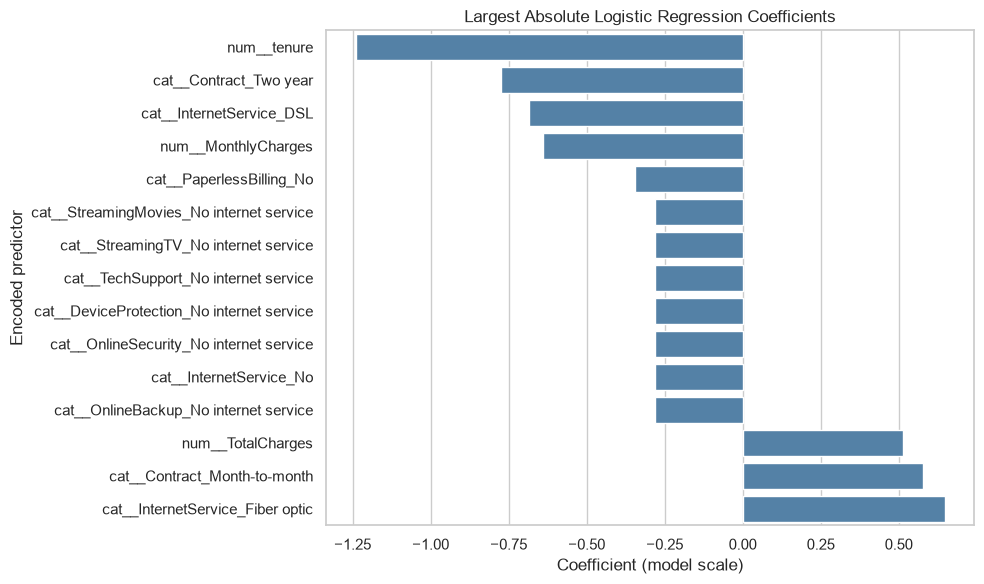

In [11]:
feature_names = model.named_steps['preprocessor'].get_feature_names_out()
coefficients = pd.DataFrame({'feature': feature_names, 'coefficient': model.named_steps['classifier'].coef_[0]})
coefficients['abs_coefficient'] = coefficients['coefficient'].abs()
coefficients = coefficients.sort_values('abs_coefficient', ascending=False)
display(coefficients.head(15).round(3))
coefficients.to_csv(REPORT_DIR / 'baseline_coefficients.csv', index=False)
fig, ax = plt.subplots(figsize=(10, 6))
plot_data = coefficients.head(15).sort_values('coefficient')
sns.barplot(data=plot_data, x='coefficient', y='feature', color='steelblue', ax=ax)
ax.set(title='Largest Absolute Logistic Regression Coefficients', xlabel='Coefficient (model scale)', ylabel='Encoded predictor')
fig.tight_layout(); fig.savefig(FIG_DIR / '07_model_coefficients.png', dpi=160, bbox_inches='tight'); plt.show()

In [12]:
from pathlib import Path

print("Figures:")
for file in sorted(FIG_DIR.glob("*.png")):
    print("✓", file.name)

print("\nReports:")
for file in sorted(REPORT_DIR.glob("*.csv")):
    print("✓", file.name)

Figures:
✓ 01_churn_distribution.png
✓ 02_categorical_churn_rates.png
✓ 03_numeric_distributions.png
✓ 04_numeric_correlations.png
✓ 05_engineered_features.png
✓ 06_baseline_evaluation.png
✓ 07_model_coefficients.png

Reports:
✓ baseline_coefficients.csv
✓ baseline_metrics.csv
✓ outlier_audit.csv


## Results and Business Implications
The detailed findings below connect the exploratory patterns and held-out baseline results to the original research question. Segment differences are descriptive associations; proposed retention actions require validation through experiments or prospective monitoring.


### Key Findings, Limitations, and Module 24 Next Steps
### Measured findings
- **Overall churn:** 1,869 of 7,043 customers (26.54%).
- **Contract:** month-to-month customers had 42.71% churn, versus 11.27% for one-year contracts and 2.83% for two-year contracts.
- **Payment method:** electronic-check customers had 45.29% churn, compared with 15.24% for automatic credit-card payments.
- **Internet service:** fiber-optic customers had 41.89% churn, compared with 18.96% for DSL and 7.40% for customers without internet service.
- **Data quality:** 11 blank `TotalCharges` values were identified and handled with training-only median imputation; no duplicate customer IDs were detected.
- **Baseline held-out performance:** accuracy **0.8055**, precision **0.6572**, recall **0.5588**, F1 **0.6040**, ROC-AUC **0.8419**, and average precision **0.6334**.

### Interpretation
The baseline identifies approximately **55.9%** of churned customers at the default 0.50 threshold. This leaves meaningful room to improve recall and evaluate outreach workload in Module 24. Observed segment differences are **associations**, not causal evidence that switching contracts or payment methods prevents churn.

### Operational implications to test
Review onboarding and customer-success support for short-tenure and month-to-month customers; investigate friction associated with electronic-check payment and fiber-optic service segments. Test interventions through a controlled pilot before claiming business impact.

### Limitations
This is observational, cross-sectional telecom data, **not** verified Salesforce renewal opportunities or SaaS renewals. The dataset does not establish when every predictor became available, and model generalization to future customers is unverified. Correlated predictors limit coefficient-level interpretation.

### Module 24 next steps
Compare Decision Tree, Random Forest, and other appropriate classifiers using stratified cross-validation and GridSearchCV **on training data**, investigate thresholds and precision–recall tradeoffs, and preserve the held-out test set for final evaluation. Quantify operational costs, fairness, and privacy considerations before deployment.

## Conclusion
The Module 20.1 analysis establishes an auditable EDA workflow and a reproducible Logistic Regression benchmark. The observed churn patterns can help prioritize questions for customer-success teams, while the **55.88% recall** highlights the need to evaluate alternative models and decision thresholds in Module 24. Findings should not be treated as causal or directly transferable to Salesforce renewal outcomes without further validation.

**Project navigation:** See the accompanying `README.md` for the executive-level report and links to the notebook, figures, and CSV outputs.